# Notebook 04 — Componente no supervisado: segmentación de visitantes

**Problema:** descubrir **tipos de visitantes según cómo navegan**, sin usar `Revenue`. Es una pregunta distinta a la del notebook 03: allí se predice *un resultado conocido*; aquí se busca *estructura que no sabíamos que existía*.

**Reglas de diseño**
1. **`Revenue` no entra al agrupamiento** (requisito del enunciado). Solo se usa *después*, para interpretar los grupos.
2. Se usan solo **variables de conducta de navegación** (páginas visitadas, duraciones, tasas de rebote y salida). Se **excluye `PageValues`** por contener información del resultado (notebook 01) y `SpecialDay` por ser un dato de calendario, no de conducta.
3. No hay conjunto de prueba: el agrupamiento no predice, describe. El escalador se ajusta con todas las sesiones porque no se usa ninguna etiqueta.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Rutas del proyecto (los notebooks viven en evaluacion 4/notebooks)
RAIZ = Path('..').resolve()
DATOS = RAIZ / 'data' / 'online_shoppers_intention.csv'
FIG = RAIZ / 'figuras'
RES = RAIZ / 'resultados'
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

# Estilo comun a todos los graficos del proyecto
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.figsize': (9, 4.5), 'axes.titleweight': 'bold',
                     'axes.spines.top': False, 'axes.spines.right': False})
AZUL, NARANJA, GRIS, VERDE, ROJO = '#1F4E79', '#E8833A', '#8C8C8C', '#3B8E5A', '#C0392B'
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

sys.path.insert(0, str(RAIZ / 'src'))
from preprocesamiento import (cargar_datos, dividir_train_test, construir_preprocesador, matriz_conducta,
                              NUMERICAS, CATEGORICAS, BINARIAS, CONDUCTA, OBJETIVO, SEMILLA, MESES_ORDEN)

In [2]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score

df = cargar_datos()
X, escala = matriz_conducta(df)           # log1p + estandarizacion de las 8 variables de conducta
print(f'{X.shape[0]:,} sesiones x {X.shape[1]} variables de conducta:', CONDUCTA)

12,205 sesiones x 8 variables de conducta: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']


## 1. Algoritmos seleccionados y por qué

| Algoritmo | Idea | Supuestos | Ventajas | Limitaciones aquí |
|---|---|---|---|---|
| **K-Means** | Agrupa por cercanía a un centroide | Grupos **esféricos y de tamaño parecido**; requiere elegir *k* | Rápido, simple, interpretable | Sensible a atípicos y escala; no admite grupos alargados |
| **Gaussian Mixture (GMM)** | Cada grupo es una **distribución normal** con su propia forma; asignación **probabilística** | Los datos vienen de una mezcla de normales | Grupos elípticos de distinto tamaño; da incertidumbre de pertenencia | Más parámetros; sensible a inicialización; las colas largas violan la normalidad |
| **Aglomerativo (Ward)** | Une sesiones de abajo hacia arriba minimizando la varianza interna | Distancia euclídea; no necesita inicialización | Determinista, no depende de la semilla, produce un dendrograma | Costo cuadrático en memoria; no reasigna errores tempranos |

Se comparan los **tres** (mínimo exigido: dos) porque cada uno asume una "forma" distinta de grupo: si los tres encuentran estructura parecida, la estructura es robusta.

## 2. Métricas de calidad del agrupamiento

| Métrica | Qué mide | Mejor |
|---|---|---|
| **Silhouette** | Qué tan cerca está cada sesión de su grupo frente al grupo vecino (−1 a 1) | Más alta |
| **Davies-Bouldin** | Razón entre dispersión interna y separación entre grupos | **Más baja** |
| **Calinski-Harabasz** | Razón entre dispersión entre grupos e interna | Más alta |

## 3. K-Means: ¿cuántos grupos (k)?
Se prueban de 2 a 8 grupos y se miran **inercia (codo)**, **silhouette**, **Davies-Bouldin** y **Calinski-Harabasz**. Ninguna métrica decide sola: se busca un k donde coincidan varias y donde los grupos sean **interpretables para el negocio**.

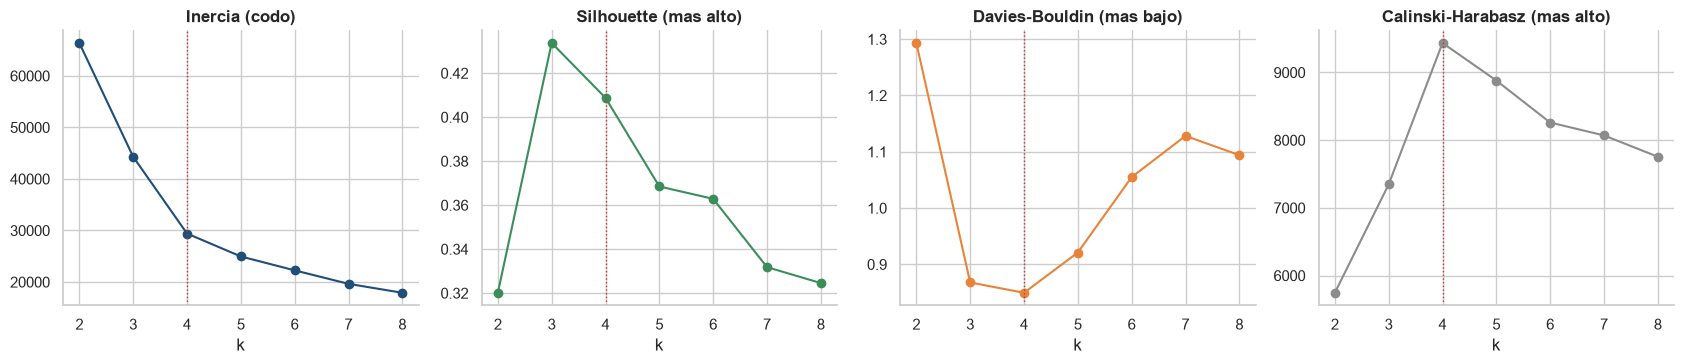

,inercia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,"66,384.923",0.320,1.293,"5,745.374"
3,"44,298.258",0.434,0.868,"7,346.522"
4,"29,408.017",0.409,0.850,"9,436.184"
5,"24,960.617",0.368,0.921,"8,880.876"
6,"22,263.415",0.363,1.055,"8,260.368"
7,"19,647.066",0.332,1.128,"8,070.400"
8,"17,913.178",0.325,1.094,"7,755.098"


In [3]:
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(X)
    filas.append({'k': k, 'inercia': km.inertia_, 'silhouette': silhouette_score(X, km.labels_),
                  'davies_bouldin': davies_bouldin_score(X, km.labels_), 'calinski_harabasz': calinski_harabasz_score(X, km.labels_)})
sel_k = pd.DataFrame(filas).set_index('k')

fig, axs = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col, tit, c in zip(axs, ['inercia', 'silhouette', 'davies_bouldin', 'calinski_harabasz'],
                           ['Inercia (codo)', 'Silhouette (mas alto)', 'Davies-Bouldin (mas bajo)', 'Calinski-Harabasz (mas alto)'],
                           [AZUL, VERDE, NARANJA, GRIS]):
    ax.plot(sel_k.index, sel_k[col], marker='o', color=c); ax.set_title(tit); ax.set_xlabel('k')
    ax.axvline(4, color=ROJO, ls=':', lw=1)
plt.tight_layout()
plt.savefig(FIG / '04_kmeans_seleccion_k.png', dpi=150, bbox_inches='tight')
plt.show()
sel_k

**Elección de k = 4**

| k | Inercia | Silhouette | Davies-Bouldin | Calinski-Harabasz |
|---|---|---|---|---|
| 2 | 66.385 | 0,320 | 1,293 | 5.745 |
| 3 | 44.298 | **0,434** | 0,868 | 7.347 |
| **4** | 29.408 | 0,409 | **0,850** | **9.436** |
| 5 | 24.961 | 0,368 | 0,921 | 8.881 |

- **Silhouette** es máximo en k = 3 (0,434) pero k = 4 queda muy cerca (0,409). **Davies-Bouldin es mínimo y Calinski-Harabasz máximo en k = 4**: dos de tres métricas favorecen k = 4.
- El **codo** de la inercia es suave (no hay un quiebre nítido): después de k = 4 las mejoras se hacen cada vez menores.
- Con k = 3 se fusionan visitantes de perfiles distintos; k = 4 separa un grupo pequeño muy diferenciado (los que rebotan) y grupos interpretables. **Se elige k = 4 por consenso de las métricas y por interpretabilidad**, reconociendo que k = 3 es una alternativa válida.
- Un silhouette de 0,41 indica una **estructura razonable pero no excelente** (>0,5 sería fuerte): los grupos se tocan en los bordes.

## 4. Los tres algoritmos con k = 4

### 4.1 Gaussian Mixture: el criterio BIC
Para el GMM se usa el **BIC** (criterio de información bayesiano: premia el ajuste y penaliza la complejidad). Se compara con los otros métodos con el mismo k.

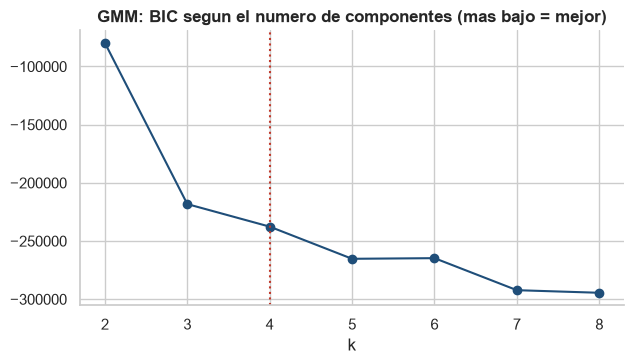

In [4]:
bic = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type='full', n_init=3, random_state=SEMILLA).fit(X)
    bic.append(g.bic(X))
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(range(2, 9), bic, marker='o', color=AZUL); ax.axvline(4, color=ROJO, ls=':')
ax.set_title('GMM: BIC segun el numero de componentes (mas bajo = mejor)'); ax.set_xlabel('k')
plt.tight_layout(); plt.savefig(FIG / '04_gmm_bic.png', dpi=150, bbox_inches='tight'); plt.show()

**El BIC no ayuda a elegir k aquí:** disminuye de forma continua de k = 2 (−79.777) a k = 8 (−294.456), sin un mínimo claro. Eso ocurre cuando los datos **no son realmente una mezcla de normales** (las variables tienen colas largas y muchos ceros, incluso en log) y el GMM sigue "ganando" al añadir componentes para ajustar la forma. Se usa k = 4 en el GMM **para comparar en igualdad de condiciones** con los otros dos algoritmos, no porque el BIC lo indique.

### 4.2 Comparación en igualdad de condiciones (k = 4)

In [5]:
K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=SEMILLA).fit(X)
gmm = GaussianMixture(n_components=K, covariance_type='full', n_init=3, random_state=SEMILLA).fit(X)
agg = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X)
etiquetas = {'K-Means': km.labels_, 'Gaussian Mixture': gmm.predict(X), 'Aglomerativo (Ward)': agg.labels_}

comp = pd.DataFrame({
    nombre: {'silhouette': silhouette_score(X, l), 'davies_bouldin': davies_bouldin_score(X, l),
             'calinski_harabasz': calinski_harabasz_score(X, l), 'tamano del grupo mas pequeno': int(np.bincount(l).min()),
             'tamano del grupo mas grande': int(np.bincount(l).max())}
    for nombre, l in etiquetas.items()}).T
comp

,silhouette,davies_bouldin,calinski_harabasz,tamano del grupo mas pequeno,tamano del grupo mas grande
K-Means,0.409,0.850,"9,436.184",796.000,"4,991.000"
Gaussian Mixture,0.377,0.865,"7,922.825",575.000,"4,624.000"
Aglomerativo (Ward),0.395,0.836,"8,521.026",577.000,"4,779.000"


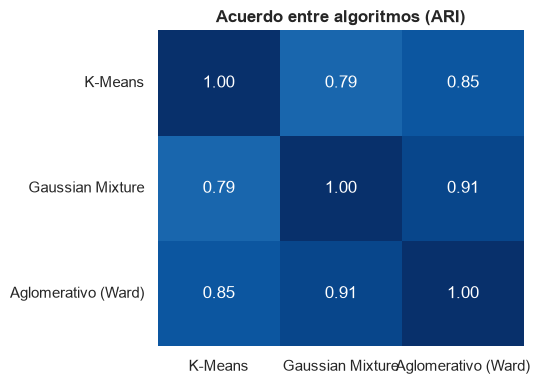

In [6]:
# Acuerdo entre algoritmos (ARI: 1 = misma particion, 0 = como al azar)
nombres = list(etiquetas)
acuerdo = pd.DataFrame([[adjusted_rand_score(etiquetas[a], etiquetas[b]) for b in nombres] for a in nombres], index=nombres, columns=nombres)
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(acuerdo, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, cbar=False, ax=ax)
ax.set_title('Acuerdo entre algoritmos (ARI)')
plt.tight_layout(); plt.savefig(FIG / '04_acuerdo_algoritmos.png', dpi=150, bbox_inches='tight'); plt.show()

**Comparación de los tres algoritmos (k = 4)**

| Algoritmo | Silhouette | Davies-Bouldin | Calinski-Harabasz | Tamaño del grupo más pequeño |
|---|---|---|---|---|
| **K-Means** | **0,409** | 0,850 | **9.436** | 796 |
| Gaussian Mixture | 0,377 | 0,865 | 7.923 | 575 |
| Aglomerativo (Ward) | 0,395 | **0,836** | 8.521 | 577 |

- **K-Means** es el mejor en silhouette y Calinski-Harabasz; el **Aglomerativo** es ligeramente mejor en Davies-Bouldin. Las diferencias son **pequeñas**: ningún algoritmo domina.
- **Los tres encuentran una estructura muy parecida:** ARI entre K-Means y GMM = 0,79; K-Means y Aglomerativo = 0,85; GMM y Aglomerativo = 0,91 (1 = idénticos). Cuando algoritmos con supuestos distintos coinciden, la estructura es **robusta**, no un artefacto de un método.
- El GMM tiene el peor silhouette porque asume grupos normales y la distribución no lo es.
- **Se elige K-Means** para el análisis posterior: mejores métricas, más rápido y con centroides interpretables.

### 4.3 Estabilidad: ¿los grupos cambian si cambian los datos o la semilla?
Un agrupamiento útil debe ser **estable**. Se mide de dos formas: (1) repitiendo K-Means con 20 semillas distintas y (2) ajustando sobre **submuestras del 80 %** y comparando con la partición de referencia (ARI sobre las sesiones comunes).

In [7]:
rng = np.random.default_rng(SEMILLA)
ari_semillas = [adjusted_rand_score(km.labels_, KMeans(K, n_init=10, random_state=s).fit(X).labels_) for s in range(100, 120)]

ari_submuestra = []
for _ in range(20):
    idx = rng.choice(len(X), int(.8 * len(X)), replace=False)
    sub = KMeans(K, n_init=10, random_state=int(rng.integers(1e6))).fit(X[idx])
    ari_submuestra.append(adjusted_rand_score(km.labels_[idx], sub.labels_))

estab = pd.DataFrame({'ARI medio': [np.mean(ari_semillas), np.mean(ari_submuestra)],
                      'ARI minimo': [np.min(ari_semillas), np.min(ari_submuestra)]},
                     index=['20 semillas distintas', '20 submuestras del 80 %'])
estab

,ARI medio,ARI minimo
20 semillas distintas,1.000,0.999
20 submuestras del 80 %,0.997,0.995


**Los grupos son muy estables.**
- Repetir K-Means con **20 semillas distintas** da exactamente la misma partición (ARI medio 1,000; mínimo 0,999).
- Con **submuestras del 80 %** la partición se mantiene (ARI medio 0,997; mínimo 0,995).
- Esto indica que los 4 grupos **no dependen de la inicialización ni de unas pocas sesiones**. (Estabilidad no es lo mismo que "verdad": un método puede ser estable y aun así imponer una estructura; por eso se contrastó con otros dos algoritmos.)

## 5. Visualización y reducción de dimensionalidad

Las 8 variables no se pueden dibujar a la vez. Se proyectan a 2 dimensiones con dos técnicas que **pierden información de distinta manera**:
- **PCA**: proyección lineal que conserva la **varianza global**; las distancias grandes se respetan, las pequeñas se aplastan.
- **t-SNE**: proyección no lineal que conserva la **vecindad local** (quién está cerca de quién); las distancias entre grupos lejanos y los tamaños **no son interpretables**.

In [8]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
Z_pca = pca.transform(X)
print(f'PCA: los 2 primeros componentes conservan {pca.explained_variance_ratio_.sum():.1%} de la varianza '
      f'(PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%})')

# t-SNE es costoso: se usa una muestra aleatoria de 5.000 sesiones (se declara en el grafico)
rng = np.random.default_rng(SEMILLA)
idx = rng.choice(len(X), 5000, replace=False)
Z_tsne = TSNE(n_components=2, perplexity=40, init='pca', random_state=SEMILLA).fit_transform(X[idx])

PCA: los 2 primeros componentes conservan 73.7% de la varianza (PC1 52.3%, PC2 21.5%)


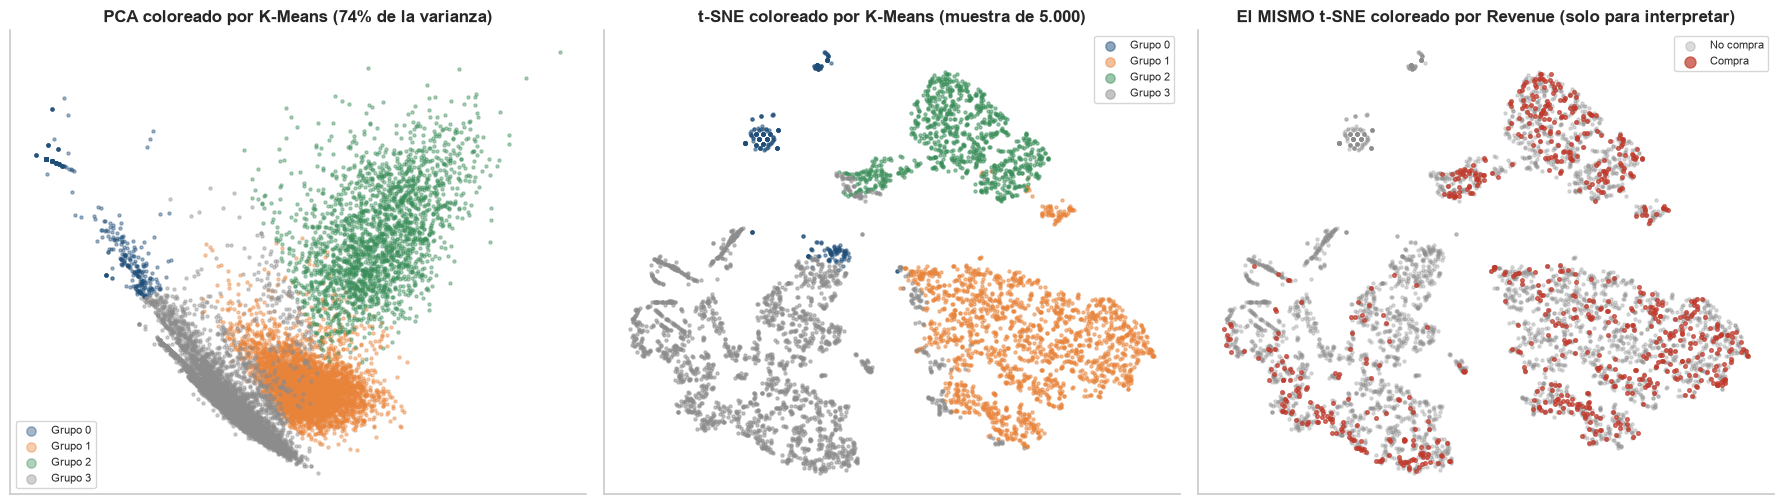

In [9]:
lab = etiquetas['K-Means']
paleta = [AZUL, NARANJA, VERDE, GRIS]
fig, axs = plt.subplots(1, 3, figsize=(18, 5.2))
for g in range(K):
    m = lab == g
    axs[0].scatter(Z_pca[m, 0], Z_pca[m, 1], s=5, alpha=.4, color=paleta[g], label=f'Grupo {g}')
    mt = lab[idx] == g
    axs[1].scatter(Z_tsne[mt, 0], Z_tsne[mt, 1], s=5, alpha=.5, color=paleta[g], label=f'Grupo {g}')
axs[0].set_title(f'PCA coloreado por K-Means ({pca.explained_variance_ratio_.sum():.0%} de la varianza)')
axs[1].set_title('t-SNE coloreado por K-Means (muestra de 5.000)')
rev = df['Revenue'].values
axs[2].scatter(Z_tsne[rev[idx] == 0, 0], Z_tsne[rev[idx] == 0, 1], s=5, alpha=.3, color=GRIS, label='No compra')
axs[2].scatter(Z_tsne[rev[idx] == 1, 0], Z_tsne[rev[idx] == 1, 1], s=7, alpha=.7, color=ROJO, label='Compra')
axs[2].set_title('El MISMO t-SNE coloreado por Revenue (solo para interpretar)')
for a in axs: a.legend(markerscale=3, fontsize=8); a.set_xticks([]); a.set_yticks([])
plt.tight_layout()
plt.savefig(FIG / '04_proyecciones_pca_tsne.png', dpi=150, bbox_inches='tight')
plt.show()

**Qué se conserva y qué se pierde en cada proyección**
- **PCA** conserva el **73,7 %** de la varianza de las 8 variables de conducta (PC1 52,3 %, PC2 21,5 %). Se ve una forma de "abanico": los grupos se ordenan por **nivel de actividad** (de los rebotadores arriba a la izquierda, a los navegantes intensos arriba a la derecha). **Pierde el 26 % de la varianza**, y por eso en 2D los grupos 1 y 3 se solapan.
- **t-SNE** separa mejor los grupos porque conserva la **vecindad local**, pero **sus distancias entre islas no significan nada** y el tamaño de las nubes tampoco; cambia con la semilla y la perplejidad. Se usa solo para ver si los grupos son cohesivos (lo son) y se calculó con una muestra de 5.000 sesiones.
- **Derecha (mismo t-SNE coloreado por `Revenue`):** las compras (rojo) **se reparten dentro de los grupos** de navegación; solo el grupo de rebotadores (pequeñas islas arriba a la izquierda) es casi todo "no compra". Es decir, **la forma de navegar organiza a los visitantes, pero no separa a los que compran de los que no**.

## 6. Perfiles de los segmentos (K-Means, k = 4)

Los nombres se asignan **por el perfil de cada grupo** (no por su número, que cambia entre ejecuciones).

In [10]:
d = df.assign(grupo=lab)
resumen_g = d.groupby('grupo').agg(sesiones=('grupo', 'size'), paginas_admin=('Administrative', 'mean'), paginas_info=('Informational', 'mean'),
                                   paginas_producto=('ProductRelated', 'mean'), seg_producto_mediana=('ProductRelated_Duration', 'median'),
                                   rebote=('BounceRates', 'mean'), salida=('ExitRates', 'mean'),
                                   nuevos=('VisitorType', lambda s: (s == 'New_Visitor').mean()), fin_semana=('Weekend', 'mean'))
nombre = {}
nombre[resumen_g['rebote'].idxmax()] = 'Rebotadores'
resto = resumen_g.drop(index=list(nombre))
nombre[resto['paginas_producto'].idxmax()] = 'Navegantes intensos'
resto = resumen_g.drop(index=list(nombre))
nombre[resto['paginas_admin'].idxmax()] = 'Exploradores con cuenta'
nombre[resto['paginas_admin'].idxmin()] = 'Consultores rapidos de producto'
d['segmento'] = d['grupo'].map(nombre)
resumen_g['segmento'] = resumen_g.index.map(nombre)
resumen_g['% de sesiones'] = resumen_g['sesiones'] / len(d) * 100
resumen_g.set_index('segmento').sort_values('sesiones', ascending=False)

,sesiones,paginas_admin,paginas_info,paginas_producto,seg_producto_mediana,rebote,salida,nuevos,fin_semana,% de sesiones
segmento,,,,,,,,,,
Consultores rapidos de producto,4991,0.083,0.051,18.472,365.167,0.013,0.044,0.102,0.220,40.893
Exploradores con cuenta,4205,3.979,0.047,35.869,801.510,0.006,0.022,0.219,0.241,34.453
Navegantes intensos,2213,5.139,2.593,66.114,"1,679.667",0.007,0.022,0.105,0.272,18.132
Rebotadores,796,0.038,0.019,2.241,0.000,0.174,0.186,0.038,0.183,6.522


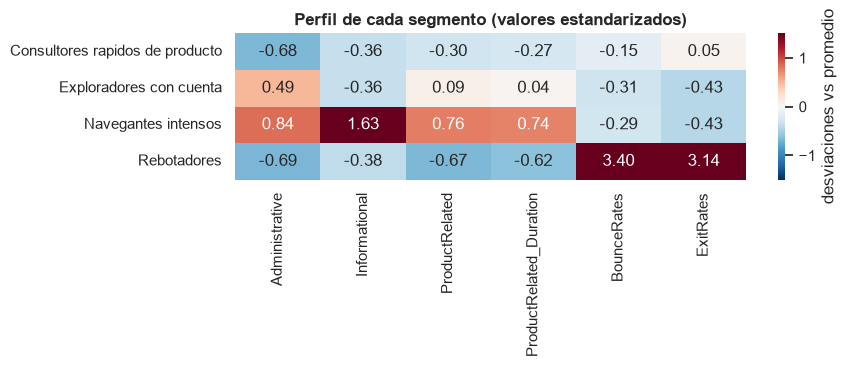

In [11]:
cols_perfil = ['Administrative', 'Informational', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates']
z = (d.groupby('segmento')[cols_perfil].mean() - d[cols_perfil].mean()) / d[cols_perfil].std()
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(z, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1.5, vmax=1.5, cbar_kws={'label': 'desviaciones vs promedio'}, ax=ax)
ax.set_title('Perfil de cada segmento (valores estandarizados)'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(FIG / '04_perfil_segmentos.png', dpi=150, bbox_inches='tight'); plt.show()

## 7. ¿Qué relación tienen los segmentos con comprar? (uso posterior de `Revenue`)
Ahora sí se usa la etiqueta, **solo para interpretar** lo que el algoritmo encontró sin verla.

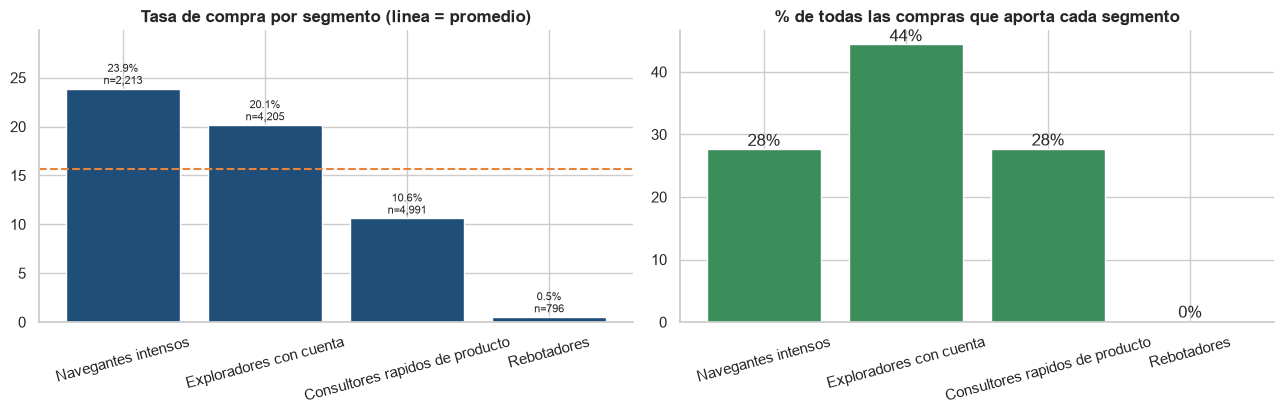

ARI entre segmentos y Revenue: 0.011 | NMI: 0.025   (0 = sin relacion)


,sesiones,compras,tasa_compra,PageValues_medio,PageValues_mayor_0,% de las compras
segmento,,,,,,
Navegantes intensos,2213,528,0.239,8.414,0.442,27.673
Exploradores con cuenta,4205,847,0.201,8.123,0.298,44.392
Consultores rapidos de producto,4991,529,0.106,3.974,0.100,27.725
Rebotadores,796,4,0.005,0.000,0.000,0.210


In [12]:
rel = d.groupby('segmento').agg(sesiones=('Revenue', 'size'), compras=('Revenue', 'sum'), tasa_compra=('Revenue', 'mean'),
                                PageValues_medio=('PageValues', 'mean'), PageValues_mayor_0=('PageValues', lambda s: (s > 0).mean()))
rel['% de las compras'] = rel['compras'] / rel['compras'].sum() * 100
rel = rel.sort_values('tasa_compra', ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.3))
axs[0].bar(rel.index, rel['tasa_compra'] * 100, color=AZUL)
for i, (t, n) in enumerate(zip(rel['tasa_compra'], rel['sesiones'])):
    axs[0].text(i, t * 100 + .5, f'{t:.1%}\nn={n:,}', ha='center', fontsize=8)
axs[0].axhline(d['Revenue'].mean() * 100, ls='--', color=NARANJA); axs[0].set_ylim(0, rel['tasa_compra'].max() * 100 * 1.25)
axs[0].set_title('Tasa de compra por segmento (linea = promedio)'); axs[0].tick_params(axis='x', rotation=15)
axs[1].bar(rel.index, rel['% de las compras'], color=VERDE)
for i, v in enumerate(rel['% de las compras']): axs[1].text(i, v + .5, f'{v:.0f}%', ha='center')
axs[1].set_title('% de todas las compras que aporta cada segmento'); axs[1].tick_params(axis='x', rotation=15)
plt.tight_layout(); plt.savefig(FIG / '04_segmentos_vs_revenue.png', dpi=150, bbox_inches='tight'); plt.show()

print(f'ARI entre segmentos y Revenue: {adjusted_rand_score(d["Revenue"], d["grupo"]):.3f} | '
      f'NMI: {normalized_mutual_info_score(d["Revenue"], d["grupo"]):.3f}   (0 = sin relacion)')
rel

In [13]:
# Se guardan resultados para el notebook 05 y la documentacion
comp.round(4).to_csv(RES / 'metricas_clustering.csv')
resumen_g.set_index('segmento').round(4).to_csv(RES / 'perfiles_segmentos.csv')
rel.round(4).to_csv(RES / 'segmentos_vs_revenue.csv')
d[['segmento']].to_csv(RES / 'segmento_por_sesion.csv')          # el indice es el de cargar_datos()
sel_k.round(4).to_csv(RES / 'kmeans_seleccion_k.csv')
print('Guardado en resultados/')

Guardado en resultados/


## Perfiles de los 4 segmentos y su relación con la compra

| Segmento | Sesiones | Perfil de navegación (promedios) | Tasa de compra | % de todas las compras |
|---|---|---|---|---|
| **Consultores rápidos de producto** | 4.991 (40,9 %) | Casi no visitan páginas administrativas (0,08); **18 páginas de producto**, mediana de ~6 min (365 s); salida baja (4,4 %) | **10,6 %** | 27,7 % |
| **Exploradores con cuenta** | 4.205 (34,5 %) | **4,0 páginas administrativas**; 36 páginas de producto, ~13 min (802 s); **rebote y salida muy bajos** (0,6 % / 2,2 %); 22 % son visitantes nuevos | **20,1 %** | **44,4 %** |
| **Navegantes intensos** | 2.213 (18,1 %) | 5,1 administrativas, 2,6 informativas y **66 páginas de producto**, ~28 min (1.680 s) | **23,9 %** (la más alta) | 27,7 % |
| **Rebotadores** | 796 (6,5 %) | **2 páginas de producto y 0 segundos** en ellas; rebote 17 % y salida 19 % | **0,5 %** (4 compras en 796) | 0,2 % |

**Lo que descubrió el algoritmo sin ver la etiqueta**
- Los segmentos **ordenan a los visitantes por compromiso y estos órdenes coinciden con la tasa de compra** (0,5 % → 10,6 % → 20,1 % → 23,9 %), aunque `Revenue` nunca se usó para agruparlos.
- **Sorpresa:** el grupo **con más compras en total son los "Exploradores con cuenta" (44 %)**, no los "Navegantes intensos" (que compran más por sesión pero son menos). El comportamiento "visitar páginas administrativas" (cuenta, perfil) distingue a quienes compran con más frecuencia.
- Los **Rebotadores son un grupo claramente identificable y casi nunca compran**: no vale la pena gastar recursos de retención en ellos, sino mejorar la entrada al sitio.
- **ARI = 0,011 y NMI = 0,025 entre grupos y `Revenue`:** como *partición*, el agrupamiento **no coincide** con "compra / no compra". Los grupos describen *cómo* navegan, no *si* compran. Son preguntas distintas, y por eso los dos enfoques se complementan.